In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm

os.makedirs("outputs", exist_ok=True)
pd.options.display.float_format = "{:,.4f}".format

TICKERS     = ["SPY", "AAPL", "TSLA"]
EST_START, EST_END   = "2015-01", "2022-12"        # estimation window
TEST_START, TEST_END = "2023-01-01", "2025-12-31"  # frozen test window
FACTORS_5 = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]


In [2]:
# Kenneth French 5 factors (monthly, in % -> converted to decimals)
ff = pd.read_csv("data/raw/F-F_Research_Data_5_Factors_2x3.csv", skiprows=3, index_col=0)
ff.index = ff.index.astype(str).str.strip()
ff = ff[ff.index.str.match(r"^\d{6}$")].apply(pd.to_numeric, errors="coerce") / 100
ff.index = pd.PeriodIndex(pd.to_datetime(ff.index, format="%Y%m"), freq="M")

# Monthly stock returns
rets = pd.read_csv("data/processed/stock_monthly_returns.csv", index_col=0, parse_dates=True)
rets.index = rets.index.to_period("M")

data = rets[TICKERS].join(ff, how="inner").loc[EST_START:EST_END].dropna()
print(f"Observations used: {len(data)}  ({data.index.min()} to {data.index.max()})")
display(data.head())


Observations used: 95  (2015-02 to 2022-12)


,SPY,AAPL,TSLA,Mkt-RF,SMB,HML,RMW,CMA,RF
Date,,,,,,,,,
2015-02,0.0562,0.1008,-0.0013,0.0614,0.0039,-0.0175,-0.0110,-0.0175,0.0000
2015-03,-0.0157,-0.0314,-0.0717,-0.0109,0.0308,-0.0038,0.0007,-0.0062,0.0000
2015-04,0.0098,0.0058,0.1975,0.0060,-0.0300,0.0181,0.0005,-0.0062,0.0000
2015-05,0.0129,0.0453,0.1095,0.0138,0.0083,-0.0110,-0.0175,-0.0083,0.0000
2015-06,-0.0203,-0.0372,0.0696,-0.0154,0.0292,-0.0080,0.0035,-0.0154,0.0000


In [3]:
def star(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

long_rows, wide_rows, fits = [], [], {}
for t in TICKERS:
    y = data[t] - data["RF"]                                   # excess return
    for model_name, xcols in [("Market-only (CAPM)", ["Mkt-RF"]), ("Fama-French 5-factor", FACTORS_5)]:
        X = sm.add_constant(data[xcols])
        fit = sm.OLS(y, X).fit()
        fits[(t, model_name)] = fit

        for var in fit.params.index:
            long_rows.append({"Ticker": t, "Model": model_name,
                              "Variable": "Alpha" if var == "const" else var,
                              "Coefficient": fit.params[var], "Std Error": fit.bse[var],
                              "t-stat": fit.tvalues[var], "P-value": fit.pvalues[var],
                              "Sig.": star(fit.pvalues[var])})

        row = {"Ticker": t, "Model": model_name,
               "Alpha (monthly)": fit.params["const"], "Alpha p-value": fit.pvalues["const"],
               "Alpha (annualised)": fit.params["const"] * 12}
        for f in FACTORS_5:
            row[f"Beta {f}"] = fit.params.get(f, np.nan)
            row[f"p {f}"]    = fit.pvalues.get(f, np.nan)
        row["R-squared"], row["Adj. R-squared"], row["N"] = fit.rsquared, fit.rsquared_adj, int(fit.nobs)
        wide_rows.append(row)

reg_long = pd.DataFrame(long_rows)
reg_wide = pd.DataFrame(wide_rows)
reg_long.to_csv("outputs/factor_regression_long.csv", index=False)
reg_wide.to_csv("outputs/factor_regression_summary.csv", index=False)
print("Saved: outputs/factor_regression_long.csv, outputs/factor_regression_summary.csv")


Saved: outputs/factor_regression_long.csv, outputs/factor_regression_summary.csv


In [4]:
for t in TICKERS:
    for m in ["Market-only (CAPM)", "Fama-French 5-factor"]:
        sub = reg_long[(reg_long.Ticker == t) & (reg_long.Model == m)].drop(columns=["Ticker", "Model"]).set_index("Variable")
        f = fits[(t, m)]
        print(f"\n=== {t} | {m} | R2 = {f.rsquared:.3f} | Adj R2 = {f.rsquared_adj:.3f} | N = {int(f.nobs)} ===")
        display(sub)
print("Significance: *** p<0.01, ** p<0.05, * p<0.10")



=== SPY | Market-only (CAPM) | R2 = 0.989 | Adj R2 = 0.989 | N = 95 ===


,Coefficient,Std Error,t-stat,P-value,Sig.
Variable,,,,,
Alpha,0.0004,0.0005,0.7705,0.4429,
Mkt-RF,0.9599,0.0106,90.3499,0.0000,***



=== SPY | Fama-French 5-factor | R2 = 0.997 | Adj R2 = 0.997 | N = 95 ===


,Coefficient,Std Error,t-stat,P-value,Sig.
Variable,,,,,
Alpha,-0.0002,0.0003,-0.5791,0.5640,
Mkt-RF,0.9782,0.0066,148.2384,0.0000,***
SMB,-0.1193,0.0124,-9.6139,0.0000,***
HML,0.0203,0.0104,1.9561,0.0536,*
RMW,0.0778,0.0152,5.1284,0.0000,***
CMA,0.0204,0.0161,1.2723,0.2066,



=== AAPL | Market-only (CAPM) | R2 = 0.479 | Adj R2 = 0.473 | N = 95 ===


...


=== TSLA | Market-only (CAPM) | R2 = 0.231 | Adj R2 = 0.222 | N = 95 ===


,Coefficient,Std Error,t-stat,P-value,Sig.
Variable,,,,,
Alpha,0.0213,0.0167,1.2749,0.2055,
Mkt-RF,1.8288,0.3464,5.2800,0.0000,***



=== TSLA | Fama-French 5-factor | R2 = 0.288 | Adj R2 = 0.248 | N = 95 ===


,Coefficient,Std Error,t-stat,P-value,Sig.
Variable,,,,,
Alpha,0.0232,0.0168,1.3774,0.1719,
Mkt-RF,1.9459,0.3881,5.0145,0.0000,***
SMB,-0.4210,0.7295,-0.5770,0.5654,
HML,-0.8449,0.6105,-1.3840,0.1698,
RMW,-0.7651,0.8918,-0.8580,0.3932,
CMA,-0.1522,0.9450,-0.1611,0.8724,


Significance: *** p<0.01, ** p<0.05, * p<0.10


In [5]:
display(reg_wide.set_index(["Ticker", "Model"]))

Alpha (monthly)  Alpha p-value  \
Ticker Model                                                  
SPY    Market-only (CAPM)             0.0004         0.4429   
       Fama-French 5-factor          -0.0002         0.5640   
AAPL   Market-only (CAPM)             0.0090         0.1619   
       Fama-French 5-factor           0.0072         0.2466   
TSLA   Market-only (CAPM)             0.0213         0.2055   
       Fama-French 5-factor           0.0232         0.1719   

                             Alpha (annualised)  Beta Mkt-RF  p Mkt-RF  \
Ticker Model                                                             
SPY    Market-only (CAPM)                0.0047       0.9599    0.0000   
       Fama-French 5-factor             -0.0020       0.9782    0.0000   
AAPL   Market-only (CAPM)                0.1083       1.2246    0.0000   
       Fama-French 5-factor              0.0864       1.2359    0.0000   
TSLA   Market-only (CAPM)                0.2559       1.8288    0.0000   
       Fama-French 5-factor              0.2783       1.9459    0.0000   

                             Beta SMB  p SMB  Beta HML  p HML  Beta RMW  \
Ticker Model                                                              
SPY    Market-only (CAPM)         NaN    NaN       NaN    NaN       NaN   
       Fama-French 5-factor   -0.1193 0.0000    0.0203 0.0536    0.0778   
AAPL   Market-only (CAPM)         NaN    NaN       NaN    NaN       NaN   
       Fama-French 5-factor   -0.1929 0.4726   -0.5012 0.0276    0.4393   
TSLA   Market-only (CAPM)         NaN    NaN       NaN    NaN       NaN   
       Fama-French 5-factor   -0.4210 0.5654   -0.8449 0.1698   -0.7651   

                             p RMW  Beta CMA  p CMA  R-squared  \
Ticker Model                                                     
SPY    Market-only (CAPM)      NaN       NaN    NaN     0.9887   
       Fama-French 5-factor 0.0000    0.0204 0.2066     0.9968   
AAPL   Market-only (CAPM)      NaN       NaN    NaN     0.4789   
       Fama-French 5-factor 0.1824   -0.0767 0.8253     0.5570   
TSLA   Market-only (CAPM)      NaN       NaN    NaN     0.2306   
       Fama-French 5-factor 0.3932   -0.1522 0.8724     0.2879   

                             Adj. R-squared   N  
Ticker Model                                     
SPY    Market-only (CAPM)            0.9886  95  
       Fama-French 5-factor          0.9966  95  
AAPL   Market-only (CAPM)            0.4732  95  
       Fama-French 5-factor          0.5321  95  
TSLA   Market-only (CAPM)            0.2224  95  
       Fama-French 5-factor          0.2479  95

In [6]:
for t in TICKERS:
    capm, ff5 = fits[(t, "Market-only (CAPM)")], fits[(t, "Fama-French 5-factor")]
    sig = lambda f: "SIGNIFICANT" if f.pvalues["const"] < 0.05 else "not significant"
    print(f"{t}: CAPM beta = {capm.params['Mkt-RF']:.2f}, alpha {capm.params['const']*12:.2%}/yr ({sig(capm)}, p={capm.pvalues['const']:.3f}); "
          f"FF5 alpha {ff5.params['const']*12:.2%}/yr ({sig(ff5)}, p={ff5.pvalues['const']:.3f}); "
          f"R2 {capm.rsquared:.2f} -> {ff5.rsquared:.2f}")



SPY: CAPM beta = 0.96, alpha 0.47%/yr (not significant, p=0.443); FF5 alpha -0.20%/yr (not significant, p=0.564); R2 0.99 -> 1.00
AAPL: CAPM beta = 1.22, alpha 10.83%/yr (not significant, p=0.162); FF5 alpha 8.64%/yr (not significant, p=0.247); R2 0.48 -> 0.56
TSLA: CAPM beta = 1.83, alpha 25.59%/yr (not significant, p=0.206); FF5 alpha 27.83%/yr (not significant, p=0.172); R2 0.23 -> 0.29


In [7]:
# ---- 1) daily adjusted prices for the evaluation (download once, then offline)
EVAL_TICKERS = ["SPY", "AAPL", "MSFT", "TSLA", "QQQ"]
EVAL_FILE    = "data/raw/eval_prices_2022-12_to_2025-12.csv"

if not os.path.exists(EVAL_FILE):
    import yfinance as yf                      # needs internet, only the first time
    dl = yf.download(EVAL_TICKERS, start="2022-12-01", end="2026-01-01", auto_adjust=True, progress=False)
    dl.to_csv(EVAL_FILE)                       # untransformed download saved as the raw file
    print(f"Downloaded {EVAL_TICKERS} on {pd.Timestamp.today():%Y-%m-%d} (yfinance {yf.__version__}, auto_adjust=True) -> {EVAL_FILE}")

raw = pd.read_csv(EVAL_FILE, header=[0, 1], index_col=0)
raw.index = pd.to_datetime(raw.index, errors="coerce")
raw = raw[raw.index.notna()].sort_index()
px = raw["Close"][EVAL_TICKERS].astype(float)

base_date = px[:"2022-12-31"].index[-1]        # last trading day of 2022 = purchase date
base_px   = px.loc[base_date]
px_t      = px[TEST_START:TEST_END]
print(f"Test window: {px_t.index[0]:%d-%b-%Y} to {px_t.index[-1]:%d-%b-%Y} ({len(px_t)} trading days), purchase date = {base_date:%d-%b-%Y}")

# ---- 2) capital and required return from the portfolio notebook
if os.path.exists("outputs/required_return.csv"):
    rr = pd.read_csv("outputs/required_return.csv").iloc[0]
    CAPITAL, REQ_RET = float(rr["equity_new"]), float(rr["required_return_new"])
else:
    CAPITAL, REQ_RET = 6_534_903.52, 0.0485     # fallback - run the portfolio notebook first!
    print("WARNING: outputs/required_return.csv not found - using fallback numbers")
print(f"Growth capital = ${CAPITAL:,.2f} | Required return = {REQ_RET:.2%}")

# ---- 3) frozen strategies (buy and hold)
opt = pd.read_csv("outputs/portfolio_optimization_results.csv")
def max_sharpe_weights(model):

    row = opt[(opt["Model"] == model) & (opt["Portfolio"].str.startswith("Max-Sharpe"))].iloc[0]
    return row[[c for c in opt.columns if c in px.columns]].astype(float)

strategies = {"SPY (recommended growth = benchmark)": pd.Series({"SPY": 1.0})}
strategies["Sample-covariance optimum (Max-Sharpe)"] = max_sharpe_weights("Sample covariance")
strategies["Single-index optimum (Max-Sharpe)"]      = max_sharpe_weights("Single-index model")
display(pd.DataFrame(strategies).fillna(0.0).round(4))

values = {}
for name, w in strategies.items():
    units = CAPITAL * w / base_px[w.index]                  # units bought at the end-2022 price
    values[name] = (px_t[w.index] * units).sum(axis=1)

years = pd.Series((px_t.index - base_date).days / 365.25, index=px_t.index)
target_path = CAPITAL * (1 + REQ_RET) ** years              # reference: required-return path


Downloaded ['SPY', 'AAPL', 'MSFT', 'TSLA', 'QQQ'] on 2026-10-25 (yfinance 1.7.0, auto_adjust=True) -> data/raw/eval_prices_2022-12_to_2025-12.csv
Test window: 03-Jan-2023 to 31-Dec-2025 (752 trading days), purchase date = 30-Dec-2022
Growth capital = $6,534,903.52 | Required return = 4.85%


,SPY (recommended growth = benchmark),Sample-covariance optimum (Max-Sharpe),Single-index optimum (Max-Sharpe)
AAPL,0.0000,0.0000,0.1267
MSFT,0.0000,0.9136,0.7731
QQQ,0.0000,0.0000,0.0000
SPY,1.0000,0.0000,0.0000
TSLA,0.0000,0.0864,0.1002


In [8]:
def max_drawdown(v):
    return (v / v.cummax() - 1).min()

T = (px_t.index[-1] - base_date).days / 365.25
rows = {}
for name, v in values.items():
    rows[name] = {"Final value (USD)": v.iloc[-1],
                  "Cumulative return": v.iloc[-1] / CAPITAL - 1,
                  "Annualised return": (v.iloc[-1] / CAPITAL) ** (1 / T) - 1,
                  "Annualised volatility": v.pct_change().dropna().std() * np.sqrt(252),
                  "Max drawdown": max_drawdown(v),
                  "Excess final value vs SPY (USD)": v.iloc[-1] - values["SPY (recommended growth = benchmark)"].iloc[-1]}
perf = pd.DataFrame(rows)
display(perf)
print(f"Required-return path ends at ${target_path.iloc[-1]:,.0f}")
perf.to_csv("outputs/reality_check_performance.csv")
pd.DataFrame(values).assign(Required_return_path=target_path).to_csv("outputs/reality_check_series.csv")


,SPY (recommended growth = benchmark),Sample-covariance optimum (Max-Sharpe),Single-index optimum (Max-Sharpe)
Final value (USD),"12,122,086.5086","14,388,399.6105","14,580,857.3262"
Cumulative return,0.8550,1.2018,1.2312
Annualised return,0.2284,0.3006,0.3063
Annualised volatility,0.1535,0.2386,0.2326
Max drawdown,-0.1876,-0.2695,-0.2886
Excess final value vs SPY (USD),0.0000,"2,266,313.1019","2,458,770.8176"


Required-return path ends at $7,532,817


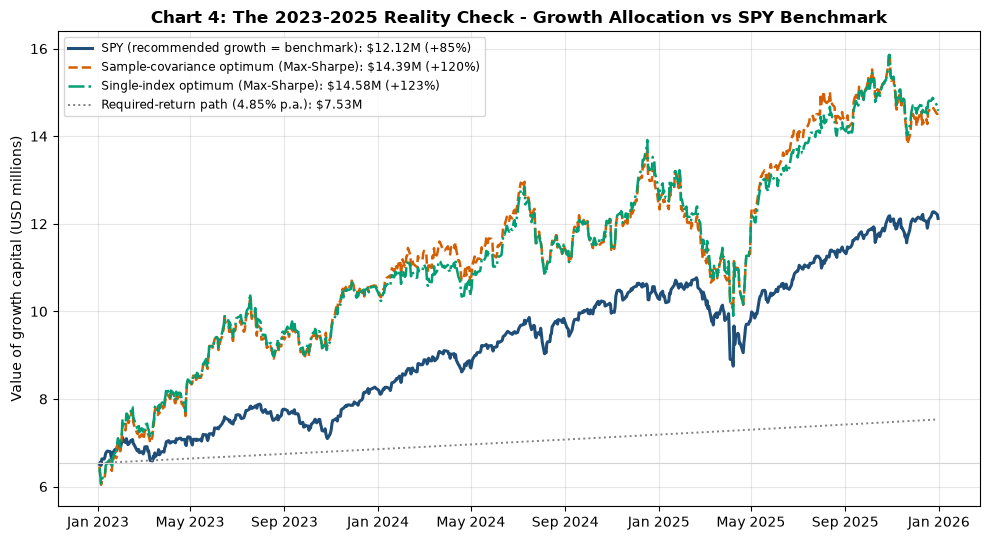

In [9]:
palette = ["#1f4e79", "#d55e00", "#009e73"]
fig, ax = plt.subplots(figsize=(10, 5.5))
for (name, v), c, ls in zip(values.items(), palette, ["-", "--", "-."]):
    ax.plot(v.index, v / 1e6, color=c, lw=2.2 if c == "#1f4e79" else 1.8, ls=ls,
            label=f"{name}: ${v.iloc[-1]/1e6:,.2f}M ({v.iloc[-1]/CAPITAL-1:+.0%})")
ax.plot(target_path.index, target_path / 1e6, color="grey", lw=1.4, ls=":",
        label=f"Required-return path ({REQ_RET:.2%} p.a.): ${target_path.iloc[-1]/1e6:,.2f}M")
ax.axhline(CAPITAL / 1e6, color="lightgrey", lw=0.8)

ax.set_title("Chart 4: The 2023-2025 Reality Check - Growth Allocation vs SPY Benchmark", fontweight="bold")
ax.set_ylabel("Value of growth capital (USD millions)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(alpha=0.3)
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
fig.savefig("outputs/chart4_reality_check.png", dpi=200)
plt.show()
